## Course ID: AIMLZG565
## Course Name: Machine Learning

## Assignment 2
### Name: Raghu Prashanka
### Student ID: 2026AJ05947

Five classifiers (Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM) trained on the same split and compared on Accuracy, AUC, Precision, Recall, F1 and MCC.
The training logic lives in `train_models.py`; this notebook runs it and shows the results.

In [1]:
import platform, sklearn, pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns, joblib, json
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Python 3.14.6 | scikit-learn 1.9.0 | pandas 3.0.3


## 1. Dataset

In [2]:
df = pd.read_csv("data/spambase.csv")
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| exact duplicates:", int(df.duplicated().sum()))
print(df["is_spam"].value_counts().rename({0: "not spam", 1: "spam"}))
df.describe().T.head(10)

Shape: (4601, 58)
Missing values: 0 | exact duplicates: 391
is_spam
not spam    2788
spam        1813
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
word_freq_make,4601.0,0.104553,0.305358,0.0,0.0,0.0,0.00,4.54
word_freq_address,4601.0,0.213015,1.290575,0.0,0.0,0.0,0.00,14.28
word_freq_all,4601.0,0.280656,0.504143,0.0,0.0,0.0,0.42,5.10
word_freq_3d,4601.0,0.065425,1.395151,0.0,0.0,0.0,0.00,42.81
word_freq_our,4601.0,0.312223,0.672513,0.0,0.0,0.0,0.38,10.00
word_freq_over,4601.0,0.095901,0.273824,0.0,0.0,0.0,0.00,5.88
word_freq_remove,4601.0,0.114208,0.391441,0.0,0.0,0.0,0.00,7.27
word_freq_internet,4601.0,0.105295,0.401071,0.0,0.0,0.0,0.00,11.11
word_freq_order,4601.0,0.090067,0.278616,0.0,0.0,0.0,0.00,5.26
word_freq_mail,4601.0,0.239413,0.644755,0.0,0.0,0.0,0.16,18.18


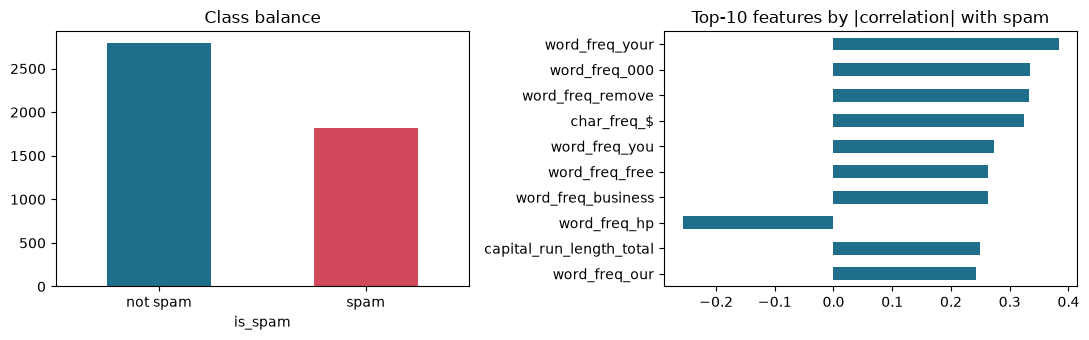

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["is_spam"].map({0: "not spam", 1: "spam"}).value_counts().plot.bar(ax=ax[0], color=["#1f6f8b", "#d1495b"])
ax[0].set_title("Class balance"); ax[0].tick_params(axis="x", rotation=0)
top = df.corr(numeric_only=True)["is_spam"].drop("is_spam").sort_values(key=abs, ascending=False).head(10)
top.plot.barh(ax=ax[1], color="#1f6f8b"); ax[1].invert_yaxis(); ax[1].set_title("Top-10 features by |correlation| with spam")
plt.tight_layout(); plt.show()

## 2. Train, tune (5-fold CV) and evaluate all five models

In [4]:
import train_models
train_models.main()

Loaded 4601 rows, 391 exact duplicates removed -> 4210 rows
Train: (3368, 57)  Test: (842, 57)  spam share train/test: 0.399/0.399
Logistic Regression      CV-F1=0.9209  Accuracy=0.9264  AUC=0.9750  Precision=0.9335  Recall=0.8780  F1=0.9049  MCC=0.8460   params={'C': 1}
Decision Tree            CV-F1=0.8970  Accuracy=0.9157  AUC=0.9219  Precision=0.9233  Recall=0.8601  F1=0.8906  MCC=0.8235   params={'criterion': 'entropy', 'max_depth': 14, 'min_samples_leaf': 1}
KNN                      CV-F1=0.9187  Accuracy=0.9264  AUC=0.9720  Precision=0.9228  Recall=0.8899  F1=0.9061  MCC=0.8459   params={'n_neighbors': 5, 'weights': 'distance'}
Naive Bayes              CV-F1=0.8238  Accuracy=0.8278  AUC=0.9537  Precision=0.7108  Recall=0.9583  F1=0.8162  MCC=0.6870   params={'var_smoothing': 0.001}
Support Vector Machine   CV-F1=0.9337  Accuracy=0.9359  AUC=0.9799  Precision=0.9462  Recall=0.8899  F1=0.9172  MCC=0.8660   params={'C': 10, 'gamma': 0.01}

Comparison table (test split):
         ML

## 3. Comparison table (held-out test split)

In [5]:
metrics = pd.read_csv("model/metrics.csv").set_index("ML Model Name")
metrics.style.format("{:.4f}").highlight_max(axis=0, color="#cfe8d5")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9264,0.9750,0.9335,0.8780,0.9049,0.8460
Decision Tree,0.9157,0.9219,0.9233,0.8601,0.8906,0.8235
KNN,0.9264,0.9720,0.9228,0.8899,0.9061,0.8459
Naive Bayes,0.8278,0.9537,0.7108,0.9583,0.8162,0.6870
Support Vector Machine,0.9359,0.9799,0.9462,0.8899,0.9172,0.8660


In [6]:
print(json.dumps(json.load(open("model/best_params.json")), indent=1))

{
 "Logistic Regression": {
  "C": 1
 },
 "Decision Tree": {
  "criterion": "entropy",
  "max_depth": 14,
  "min_samples_leaf": 1
 },
 "KNN": {
  "n_neighbors": 5,
  "weights": "distance"
 },
 "Naive Bayes": {
  "var_smoothing": 0.001
 },
 "Support Vector Machine": {
  "C": 10,
  "gamma": 0.01
 }
}


## 4. Confusion matrices of the saved models on `test_data.csv`

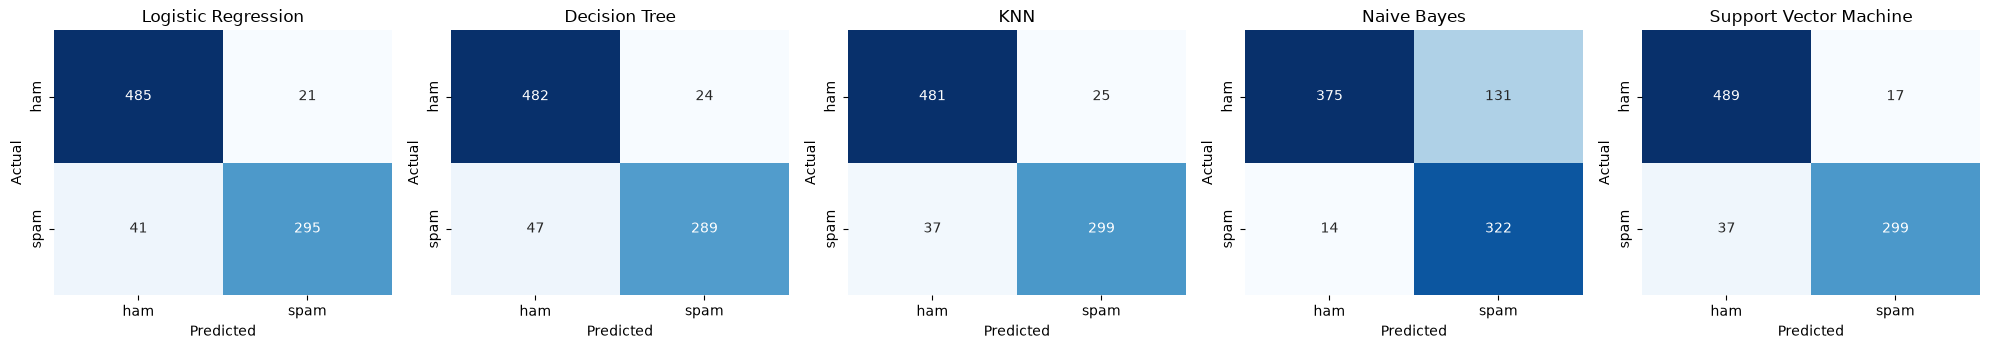

In [7]:
from sklearn.metrics import confusion_matrix
meta = json.load(open("model/meta.json"))
test = pd.read_csv("test_data.csv")
X_test, y_test = test[meta["features"]], test[meta["target"]]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, (name, f) in zip(axes, meta["models"].items()):
    m = joblib.load(f"model/{f}")
    sns.heatmap(confusion_matrix(y_test, m.predict(X_test)), annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()